<h1 align="center">ДЗ 2.2: Оптимизация вычислений в Spark</h1>

# Задание 1 Сравнение стратегий JOIN

## Запускаем спарк сессию

In [1]:
from pyspark.sql import SparkSession

In [2]:
spark = (
    SparkSession.builder
    .appName("hw22-join-strategies")
    .master("spark://spark-master:7077")
    .config("spark.driver.host", "optimization-jupyter")
    .config("spark.executor.memory", "3g")
    .config("spark.executor.cores", "4")
    .config("spark.cores.max", "4")
    .getOrCreate()
)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/13 12:06:37 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Подключаемся к S3 (RustFS)

In [3]:
# Параметры подключения к RustFS
S3_ENDPOINT = "http://rustfs:9000"
S3_ACCESS_KEY = "scd2admin"
S3_SECRET_KEY = "scd2-secret-2026"
S3_BUCKET = "spark-optimization"

# Получаем конфигурацию Hadoop
hadoop_conf = spark.sparkContext._jsc.hadoopConfiguration()

# Настройки S3A
hadoop_conf.set("fs.s3a.endpoint", S3_ENDPOINT)
hadoop_conf.set("fs.s3a.access.key", S3_ACCESS_KEY)
hadoop_conf.set("fs.s3a.secret.key", S3_SECRET_KEY)
hadoop_conf.set(
    "fs.s3a.aws.credentials.provider",
    "org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider"
)
hadoop_conf.set("fs.s3a.path.style.access", "true")
hadoop_conf.set("fs.s3a.connection.ssl.enabled", "false")
hadoop_conf.set(
    "fs.s3a.impl",
    "org.apache.hadoop.fs.s3a.S3AFileSystem"
)
print("Конфигурация S3A установлена")

Конфигурация S3A установлена


In [4]:
from py4j.java_gateway import java_import

In [5]:
java_import(spark.sparkContext._jvm, "org.apache.hadoop.fs.Path")
path = spark.sparkContext._jvm.Path(f"s3a://{S3_BUCKET}/")
fs = path.getFileSystem(hadoop_conf)

26/11/13 12:07:00 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


## Генерация данных

In [9]:
!python3 /home/jupyter/scripts/generate_event_log.py \
    --rows 5000000 \
    --users 100000 \
    --change-probability 0.20 \
    --seed 42 \
    --start-time 2026-01-01T00:00:00Z \
    --max-step-seconds 1 \
    --user-id-start 1 \
    --rows-per-file 100000 \
    --output-dir /home/jupyter/data/task1/event_log_22

files=50/50 rows=5000000/5000000 rate=174,131 rows/s
Готово: 5000000 строк в каталоге /home/jupyter/data/task1/event_log_22


Проверка

In [11]:
cat /home/jupyter/data/task1/event_log_22/_manifest.json

{
  "format": "csv",
  "columns": [
    "event_time",
    "user_id",
    "user_fio",
    "user_email",
    "user_login"
  ],
  "total_rows": 5000000,
  "rows_per_file": 100000,
  "file_count": 50,
  "user_count": 100000,
  "user_id_start": 1,
  "change_probability": 0.2,
  "applied_profile_changes": 980897,
  "seed": 42,
  "first_event_time": "2026-01-01T00:00:01Z",
  "last_event_time": "2026-02-27T20:53:20Z",
  "elapsed_seconds": 28.714
}


## Загрузим данные в S3

In [13]:
import os

Загрузим события:

In [17]:
local_dir = "/home/jupyter/data/task1/event_log_22"
s3_dir = f"s3a://{S3_BUCKET}/source/event_log_22/"
s3_path = spark.sparkContext._jvm.Path(s3_dir)
fs.mkdirs(s3_path)

uploaded = 0
skipped = 0

for f in sorted(os.listdir(local_dir)):
    if not f.endswith(".csv"):
        continue

    target_path = spark.sparkContext._jvm.Path(f"{s3_dir}{f}")
    local_path = spark.sparkContext._jvm.Path(f"file:{local_dir}/{f}")
    if fs.exists(target_path):
        skipped += 1
        continue

    fs.copyFromLocalFile(False, True, local_path, target_path)
    uploaded += 1

print(f"Загружено: {uploaded}")
print(f"Пропущено (уже существуют): {skipped}")

Загружено: 0
Пропущено (уже существуют): 50


Загрузим справочник:

In [19]:
CAMPAIGNS_LOCAL_PATH = "/home/jupyter/data/task1/campaigns.csv"
CAMPAIGNS_S3_PATH = f"s3a://{S3_BUCKET}/source/campaigns/campaigns.csv"

local_path = spark.sparkContext._jvm.Path(f"file:{CAMPAIGNS_LOCAL_PATH}")
target_path = spark.sparkContext._jvm.Path(CAMPAIGNS_S3_PATH)

if fs.exists(target_path):
    print("Справочник уже загруден")
else:
    fs.copyFromLocalFile(False, True, local_path, target_path)
    print("Справочник загружен")

Справочник уже загруден


## Читаем из S3

In [23]:
events_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(f"s3a://{S3_BUCKET}/source/event_log_22/*.csv")
)

In [24]:
print("Количество событий:", events_df.count())

Количество событий: 5000000


In [27]:
events_df.printSchema()

root
 |-- event_time: timestamp (nullable = true)
 |-- user_id: integer (nullable = true)
 |-- user_fio: string (nullable = true)
 |-- user_email: string (nullable = true)
 |-- user_login: string (nullable = true)



In [26]:
events_df.show(10, truncate=False)

+-------------------+-------+----------------+------------------------------------+----------------+
|event_time         |user_id|user_fio        |user_email                          |user_login      |
+-------------------+-------+----------------+------------------------------------+----------------+
|2026-02-26 17:06:41|62784  |Cameron Parker  |evelyn.gray.62784.r12@mail.example  |janderson62784r8|
|2026-02-26 17:06:42|21828  |William Lewis   |william.lewis.21828.r14@post.example|wlewis21828r12  |
|2026-02-26 17:06:43|98366  |Brooke Lee      |brooke.lee.98366.r6@mail.example    |blee98366r7     |
|2026-02-26 17:06:44|605    |Allison Brown   |brian.thompson.605.r9@post.example  |bthompson605r10 |
|2026-02-26 17:06:45|7027   |Madison Anderson|sophia.sanders.7027.r3@example.com  |manderson7027r6 |
|2026-02-26 17:06:46|2618   |Matthew Hill    |matthew.hill.2618.r7@mail.example   |mhill2618r6     |
|2026-02-26 17:06:47|3536   |Brian Walker    |brandon.clark.3536.r9@example.com   |bwalker3

У справочника при чтении еще преобразуем типы

In [47]:
campaigns = (
    spark.read
    .option("header", True)
    .csv(f"s3a://{S3_BUCKET}/source/campaigns/campaigns.csv")
    .withColumn("campaign_id", F.col("campaign_id").cast("integer"))
    .withColumn("send_at", F.to_timestamp("send_at"))
)

In [48]:
campaigns.printSchema()

root
 |-- campaign_id: integer (nullable = true)
 |-- email_domain: string (nullable = true)
 |-- send_at: timestamp (nullable = true)
 |-- campaign_name: string (nullable = true)



In [49]:
campaigns.show(10, truncate=False)

+-----------+---------------+-------------------+-------------+
|campaign_id|email_domain   |send_at            |campaign_name|
+-----------+---------------+-------------------+-------------+
|1          |mail.example   |2026-02-04 09:25:59|Campaign_0001|
|2          |inbox.example  |2026-01-20 07:00:16|Campaign_0002|
|3          |webmail.example|2026-02-15 01:56:37|Campaign_0003|
|4          |webmail.example|2026-02-17 23:41:49|Campaign_0004|
|5          |post.example   |2026-01-07 02:27:37|Campaign_0005|
|6          |mail.example   |2026-02-12 14:57:48|Campaign_0006|
|7          |example.com    |2026-02-14 21:44:10|Campaign_0007|
|8          |example.com    |2026-01-14 12:54:19|Campaign_0008|
|9          |example.com    |2026-02-09 16:16:48|Campaign_0009|
|10         |mail.example   |2026-01-27 07:16:13|Campaign_0010|
+-----------+---------------+-------------------+-------------+
only showing top 10 rows



## Сборка SCD2

Воспользуемся скриптом из дз 2.1:

In [36]:
from pyspark.sql.window import Window
from pyspark.sql import functions as F

In [37]:
def build_scd2(events):
    w = Window.partitionBy("user_id").orderBy("event_time")
    events_prev = events.select(
        "*",
        F.lag("user_fio").over(w).alias("prev_user_fio"),
        F.lag("user_email").over(w).alias("prev_user_email"),
        F.lag("user_login").over(w).alias("prev_user_login"),
    )
    users_history = events_prev.filter(
        F.col("prev_user_fio").isNull() |
        (F.col("user_fio") != F.col("prev_user_fio")) |
        (F.col("user_email") != F.col("prev_user_email")) |
        (F.col("user_login") != F.col("prev_user_login"))
    ).drop("prev_user_fio", "prev_user_email", "prev_user_login")
    users_history = (
        users_history
        .withColumn("valid_from", F.col("event_time"))
        .withColumn("valid_to", F.lead("event_time").over(w))
        .withColumn("is_current", F.col("valid_to").isNull())
        .drop("event_time")
    )
    return users_history

Строим scd2 для events_df:

In [38]:
users_history = build_scd2(events_df)

Сохраняем в S3:

In [39]:
users_history.write.mode("overwrite").parquet(f"s3a://{S3_BUCKET}/processed/task1/users_history/")

## Чтение scd2 таблицы из S3 с помощью Spark

In [41]:
loaded_history = spark.read.parquet(f"s3a://{S3_BUCKET}/processed/task1/users_history/")

In [59]:
loaded_history.show(truncate=False)

+-------+----------------+----------------------------------+-------------+-------------------+-------------------+----------+
|user_id|user_fio        |user_email                        |user_login   |valid_from         |valid_to           |is_current|
+-------+----------------+----------------------------------+-------------+-------------------+-------------------+----------+
|2      |Joshua Thompson |joshua.thompson.2@post.example    |jthompson2   |2026-01-01 12:28:18|2026-01-07 12:22:57|false     |
|2      |Logan Roberts   |joshua.thompson.2@post.example    |jthompson2   |2026-01-07 12:22:57|2026-01-11 23:26:16|false     |
|2      |Logan Roberts   |logan.roberts.2.r2@post.example   |jthompson2   |2026-01-11 23:26:16|2026-01-27 00:01:01|false     |
|2      |Logan Roberts   |logan.roberts.2.r3@mail.example   |jthompson2   |2026-01-27 00:01:01|2026-01-30 20:07:09|false     |
|2      |Megan Cook      |logan.roberts.2.r3@mail.example   |jthompson2   |2026-01-30 20:07:09|2026-02-09 04:00

In [43]:
loaded_history.count()

1080897

## Добавим для каждого пользователя домен email

In [52]:
history_with_domain = loaded_history.withColumn(
    "email_domain",
    F.split(F.col("user_email"), "@").getItem(1)
)

Проверка:

In [53]:
history_with_domain.select("user_email", "email_domain").show(5, truncate=False)

+-------------------------------+------------+
|user_email                     |email_domain|
+-------------------------------+------------+
|joshua.thompson.2@post.example |post.example|
|joshua.thompson.2@post.example |post.example|
|logan.roberts.2.r2@post.example|post.example|
|logan.roberts.2.r3@mail.example|mail.example|
|logan.roberts.2.r3@mail.example|mail.example|
+-------------------------------+------------+
only showing top 5 rows



## INNER JOIN

Реализуем 4 стратегии INNER JOIN витрины со справочником

Получим campaign_id, campaign_name,send_at, email_domain, user_id, user_fio, user_email и user_login.

### Автоматический JOIN

In [56]:
automatic_join = (
    campaigns.alias("c")
    .join(
        history_with_domain.alias("u"),
        (F.col("c.email_domain") == F.col("u.email_domain")) &
        (F.col("u.valid_from") <= F.col("c.send_at")) &
        (F.col("u.valid_to").isNull() | (F.col("c.send_at") < F.col("u.valid_to"))),
        "inner"
    )
    .select(
        F.col("c.campaign_id"), F.col("c.campaign_name"), F.col("c.send_at"), F.col("c.email_domain"),
        F.col("u.user_id"), F.col("u.user_fio"), F.col("u.user_email"), F.col("u.user_login")
    )
)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


Проверим физический план:

In [57]:
automatic_join.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (10)
+- Project (9)
   +- BroadcastHashJoin Inner BuildLeft (8)
      :- BroadcastExchange (4)
      :  +- Project (3)
      :     +- Filter (2)
      :        +- Scan csv  (1)
      +- Project (7)
         +- Filter (6)
            +- Scan parquet  (5)


(1) Scan csv 
Output [4]: [campaign_id#359, email_domain#360, send_at#361, campaign_name#362]
Batched: false
Location: InMemoryFileIndex [s3a://spark-optimization/source/campaigns/campaigns.csv]
PushedFilters: [IsNotNull(email_domain)]
ReadSchema: struct<campaign_id:string,email_domain:string,send_at:string,campaign_name:string>

(2) Filter
Input [4]: [campaign_id#359, email_domain#360, send_at#361, campaign_name#362]
Condition : (isnotnull(email_domain#360) AND isnotnull(cast(send_at#361 as timestamp)))

(3) Project
Output [4]: [cast(campaign_id#359 as int) AS campaign_id#367, email_domain#360, cast(send_at#361 as timestamp) AS send_at#373, campaign_name#362]
Input [4]: [campaign_id#359, email_do

Spark автоматически выбрал стратегию Broadcast Hash Join

По тз, для одной пары campaign_id и user_id должна получаться не более чем одна строка, проверим это:

In [67]:
def check_unique(t):
    print("Строк: ", t.count())
    print("Повторяющихся пар: ", t.groupBy("campaign_id", "user_id").count().filter(F.col("count") > 1).count())

In [68]:
check_unique(automatic_join)

Строк:  500233
Повторяющихся пар:  0


### Sort Merge Join

Создаём JOIN с подсказкой MERGE:

In [69]:
sort_merge_join = (
    campaigns.alias("c")
    .hint("MERGE")
    .join(
        history_with_domain.alias("u").hint("MERGE"),
        (F.col("c.email_domain") == F.col("u.email_domain")) &
        (F.col("u.valid_from") <= F.col("c.send_at")) &
        (F.col("u.valid_to").isNull() | (F.col("c.send_at") < F.col("u.valid_to"))),
        "inner"
    )
    .select(
        F.col("c.campaign_id"), F.col("c.campaign_name"),
        F.col("c.send_at"), F.col("c.email_domain"),
        F.col("u.user_id"), F.col("u.user_fio"),
        F.col("u.user_email"), F.col("u.user_login")
    )
)

Проверим физический план:

In [70]:
sort_merge_join.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (13)
+- Project (12)
   +- SortMergeJoin Inner (11)
      :- Sort (5)
      :  +- Exchange (4)
      :     +- Project (3)
      :        +- Filter (2)
      :           +- Scan csv  (1)
      +- Sort (10)
         +- Exchange (9)
            +- Project (8)
               +- Filter (7)
                  +- Scan parquet  (6)


(1) Scan csv 
Output [4]: [campaign_id#359, email_domain#360, send_at#361, campaign_name#362]
Batched: false
Location: InMemoryFileIndex [s3a://spark-optimization/source/campaigns/campaigns.csv]
PushedFilters: [IsNotNull(email_domain)]
ReadSchema: struct<campaign_id:string,email_domain:string,send_at:string,campaign_name:string>

(2) Filter
Input [4]: [campaign_id#359, email_domain#360, send_at#361, campaign_name#362]
Condition : (isnotnull(email_domain#360) AND isnotnull(cast(send_at#361 as timestamp)))

(3) Project
Output [4]: [cast(campaign_id#359 as int) AS campaign_id#367, email_domain#360, cast(send_at#361 as timestamp) A

Фактическая стратегия совпадает с физическим планом

Проверяем корректность результата:

In [71]:
check_unique(sort_merge_join)

Строк:  500233
Повторяющихся пар:  0


Сравним результат с автоматическим join:

In [72]:
automatic_join.exceptAll(sort_merge_join).count()
sort_merge_join.exceptAll(automatic_join).count()

0

=> результаты полностью совпадают

### Broadcast Hash Join 

Создаём JOIN с подсказкой BROADCAST на справочнике:

In [73]:
broadcast_join = (
    campaigns.alias("c").hint("BROADCAST")
    .join(
        history_with_domain.alias("u"),
        (F.col("c.email_domain") == F.col("u.email_domain")) &
        (F.col("u.valid_from") <= F.col("c.send_at")) &
        (F.col("u.valid_to").isNull() | (F.col("c.send_at") < F.col("u.valid_to"))),
        "inner"
    )
    .select(
        F.col("c.campaign_id"), F.col("c.campaign_name"),
        F.col("c.send_at"), F.col("c.email_domain"),
        F.col("u.user_id"), F.col("u.user_fio"),
        F.col("u.user_email"), F.col("u.user_login")
    )
)

Проверим физический план:

In [74]:
broadcast_join.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (10)
+- Project (9)
   +- BroadcastHashJoin Inner BuildLeft (8)
      :- BroadcastExchange (4)
      :  +- Project (3)
      :     +- Filter (2)
      :        +- Scan csv  (1)
      +- Project (7)
         +- Filter (6)
            +- Scan parquet  (5)


(1) Scan csv 
Output [4]: [campaign_id#359, email_domain#360, send_at#361, campaign_name#362]
Batched: false
Location: InMemoryFileIndex [s3a://spark-optimization/source/campaigns/campaigns.csv]
PushedFilters: [IsNotNull(email_domain)]
ReadSchema: struct<campaign_id:string,email_domain:string,send_at:string,campaign_name:string>

(2) Filter
Input [4]: [campaign_id#359, email_domain#360, send_at#361, campaign_name#362]
Condition : (isnotnull(email_domain#360) AND isnotnull(cast(send_at#361 as timestamp)))

(3) Project
Output [4]: [cast(campaign_id#359 as int) AS campaign_id#367, email_domain#360, cast(send_at#361 as timestamp) AS send_at#373, campaign_name#362]
Input [4]: [campaign_id#359, email_do

Фактическая стратегия совпадает с физическим планом

Проверяем корректность результата:

In [75]:
check_unique(broadcast_join)

Строк:  500233
Повторяющихся пар:  0


Сравним результат с автоматическим join (sort merge совпадает с авто, поэтому его можно не проверять):

In [76]:
automatic_join.exceptAll(broadcast_join).count()
broadcast_join.exceptAll(automatic_join).count()

0

In [ ]:
=> результаты полностью совпадают

### Shuffled Hash Join

Создаём JOIN с подсказкой SHUFFLE_HASH на справочнике:

In [79]:
shuffled_hash_join = (
    campaigns.alias("c").hint("SHUFFLE_HASH")
    .join(
        history_with_domain.alias("u"),
        (F.col("c.email_domain") == F.col("u.email_domain")) &
        (F.col("u.valid_from") <= F.col("c.send_at")) &
        (F.col("u.valid_to").isNull() | (F.col("c.send_at") < F.col("u.valid_to"))),
        "inner"
    )
    .select(
        F.col("c.campaign_id"), F.col("c.campaign_name"),
        F.col("c.send_at"), F.col("c.email_domain"),
        F.col("u.user_id"), F.col("u.user_fio"),
        F.col("u.user_email"), F.col("u.user_login")
    )
)

Проверим физический план:

In [80]:
shuffled_hash_join.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (11)
+- Project (10)
   +- ShuffledHashJoin Inner BuildLeft (9)
      :- Exchange (4)
      :  +- Project (3)
      :     +- Filter (2)
      :        +- Scan csv  (1)
      +- Exchange (8)
         +- Project (7)
            +- Filter (6)
               +- Scan parquet  (5)


(1) Scan csv 
Output [4]: [campaign_id#359, email_domain#360, send_at#361, campaign_name#362]
Batched: false
Location: InMemoryFileIndex [s3a://spark-optimization/source/campaigns/campaigns.csv]
PushedFilters: [IsNotNull(email_domain)]
ReadSchema: struct<campaign_id:string,email_domain:string,send_at:string,campaign_name:string>

(2) Filter
Input [4]: [campaign_id#359, email_domain#360, send_at#361, campaign_name#362]
Condition : (isnotnull(email_domain#360) AND isnotnull(cast(send_at#361 as timestamp)))

(3) Project
Output [4]: [cast(campaign_id#359 as int) AS campaign_id#367, email_domain#360, cast(send_at#361 as timestamp) AS send_at#373, campaign_name#362]
Input [4]: [cam

Фактическая стратегия совпадает с физическим планом

Проверяем корректность результата:

In [82]:
check_unique(shuffled_hash_join)

Строк:  500233
Повторяющихся пар:  0


Сравним результат с автоматическим join (sort merge совпадает с авто, поэтому его можно не проверять):

In [83]:
automatic_join.exceptAll(shuffled_hash_join).count()
shuffled_hash_join.exceptAll(automatic_join).count()

0

=> результаты полностью совпадают

# Эксперимент

Цель - установить поведение разных стратегий на одинаковых данных

### Сохранение исходных настроек и параметров

Настройки spark:

In [87]:
spark_orig_settings = {
    "spark.sql.adaptive.enabled": spark.conf.get("spark.sql.adaptive.enabled"),
    "spark.sql.autoBroadcastJoinThreshold": spark.conf.get("spark.sql.autoBroadcastJoinThreshold"),
    "spark.sql.shuffle.partitions": spark.conf.get("spark.sql.shuffle.partitions")
}

In [89]:
print("Исходные настройки Spark:")
for key, value in spark_orig_settings.items():
    print(f"{key}: {value}")

Исходные настройки Spark:
spark.sql.adaptive.enabled: true
spark.sql.autoBroadcastJoinThreshold: 10485760b
spark.sql.shuffle.partitions: 200


Параметры:

In [93]:
sc = spark.sparkContext
conf = sc.getConf()
executor_status = spark.sparkContext._jsc.sc().getExecutorMemoryStatus()

In [96]:
WORKER_CORES = 4
WORKER_MEMORY = "4G"

In [97]:
print("Spark version:", spark.version)
print("Executors:", executor_status.size() - 1)
print("Executor memory:", conf.get("spark.executor.memory"))
print("Executor cores:", conf.get("spark.executor.cores"))
print("Driver memory:", conf.get("spark.driver.memory"))
print("Max cores:", conf.get("spark.cores.max"))
print("Worker cores:", WORKER_CORES)
print("Worker memory:", WORKER_MEMORY)

Spark version: 3.5.3
Executors: 1
Executor memory: 3g
Executor cores: 4
Driver memory: None
Max cores: 4
Worker cores: 4
Worker memory: 4G


In [98]:
runtime = spark.sparkContext._jvm.java.lang.Runtime.getRuntime()
driver_cores = runtime.availableProcessors()
driver_memory = runtime.maxMemory() / (1024 ** 3)

print(f"Driver available CPU cores: {driver_cores}")
print(f"Driver JVM max memory: {driver_memory:.2f} GiB")

Driver available CPU cores: 10
Driver JVM max memory: 1.00 GiB


Для трёх явно заданных стратегий отключим AQE и автоматический broadcast. Число shuffle
партиций зафиксируем одинаковым, например 16. Автоматический вариант запускаем с
восстановленными исходными настройками

In [102]:
explicit_settings = {
    "spark.sql.adaptive.enabled": "false",
    "spark.sql.autoBroadcastJoinThreshold": "-1",
    "spark.sql.shuffle.partitions": "16"
}

In [103]:
def set_spark_settings(settings):
    for key, value in settings.items():
        spark.conf.set(key, value)

Проверим переключение настроек:

In [107]:
set_spark_settings(explicit_settings)
for key in explicit_settings:
    print(f"{key}: {spark.conf.get(key)}")

spark.sql.adaptive.enabled: false
spark.sql.autoBroadcastJoinThreshold: -1
spark.sql.shuffle.partitions: 16


In [108]:
set_spark_settings(spark_orig_settings)
for key in spark_orig_settings:
    print(f"{key}: {spark.conf.get(key)}")

spark.sql.adaptive.enabled: true
spark.sql.autoBroadcastJoinThreshold: 10485760b
spark.sql.shuffle.partitions: 200


## Функции измерения и проверки результатов

In [99]:
import time

Время выполнения:

In [109]:
def time_join(join_df, output_path):
    start_time = time.perf_counter()
    join_df.write.mode("overwrite").parquet(output_path)
    elapsed_time = time.perf_counter() - start_time
    return elapsed_time

Проверяем количество строк, уникальных пар (campaign_id, user_id), наличие дубликатов, число выходных файлов и полное равенство результатов всех стратегий с учётом дубликатов:

In [110]:
def compare_results(df1, df2):
    diff1 = df1.exceptAll(df2).count()
    diff2 = df2.exceptAll(df1).count()
    return diff1 == 0 and diff2 == 0

In [138]:
def check_output(output_path, reference_df):
    output_df = spark.read.parquet(output_path)
    row_count = output_df.count()
    unique_pairs = output_df.select("campaign_id", "user_id").distinct().count()
    duplicate_pairs = output_df.groupBy("campaign_id", "user_id").count().filter(F.col("count") > 1).count()
    output_dir = spark.sparkContext._jvm.Path(output_path)
    output_files = [
        f.getPath().getName()
        for f in fs.listStatus(output_dir)
        if f.getPath().getName().endswith(".parquet")
    ]
    is_equal = compare_results(output_df, reference_df)

    return {
        "rows": row_count,
        "unique_pairs": unique_pairs,
        "duplicate_pairs": duplicate_pairs,
        "files": len(output_files),
        "equal_to_avtomatic": is_equal
    }

## Прогрев

In [113]:
strategies = {
    "Automatic": automatic_join,
    "Sort Merge": sort_merge_join,
    "Broadcast Hash": broadcast_join,
    "Shuffled Hash": shuffled_hash_join
}

In [115]:
BASE_OUTPUT_PATH = f"s3a://{S3_BUCKET}/results/task1"

In [116]:
for name, df in strategies.items():
    settings = (
        spark_orig_settings
        if name == "Automatic"
        else explicit_settings
    )
    set_spark_settings(settings)
    output_path = f"{BASE_OUTPUT_PATH}/warmup/{name.replace(' ', '_')}"

    print(f"Прогрев: {name}")
    elapsed = time_join(df, output_path)
    print(f"Время прогрева: {elapsed:.2f} сек.\n")

set_spark_settings(spark_orig_settings)

Прогрев: Automatic


Время прогрева: 5.38 сек.

Прогрев: Sort Merge


Время прогрева: 3.25 сек.

Прогрев: Broadcast Hash


Время прогрева: 1.37 сек.

Прогрев: Shuffled Hash


Время прогрева: 2.13 сек.



## Основной замер

Чередуем порядок запусков:

In [120]:
run_order = [
    ["Automatic", "Sort Merge", "Broadcast Hash", "Shuffled Hash"],
    ["Sort Merge", "Broadcast Hash", "Shuffled Hash", "Automatic"],
    ["Broadcast Hash", "Shuffled Hash", "Automatic", "Sort Merge"],
    ["Shuffled Hash", "Automatic", "Sort Merge", "Broadcast Hash"],
    ["Automatic", "Broadcast Hash", "Sort Merge", "Shuffled Hash"]
]

Для каждой стратегии выполняем пять замеров

Измеряем полное время выполнения JOIN и записи результата в Parquet

Результаты каждого запуска сохраняем отдельно

In [124]:
import pandas as pd

In [129]:
measurements = []

In [132]:
for run_number, order in enumerate(run_order, start=1):
    for name in order:
        df = strategies[name]
        settings = (
            spark_orig_settings
            if name == "Automatic"
            else explicit_settings
        )
        set_spark_settings(settings)

        output_path = f"{BASE_OUTPUT_PATH}/runs/{name.replace(' ', '_')}/run_{run_number}"
        elapsed = time_join(df, output_path)

        measurements.append({
            "strategy": name,
            "run": run_number,
            "time_sec": elapsed
        })

set_spark_settings(spark_orig_settings)

In [133]:
measurements_df = pd.DataFrame(measurements)
measurements_df

,strategy,run,time_sec
0,Automatic,1,2.175421
1,Sort Merge,1,2.029843
2,Broadcast Hash,1,1.291781
3,Shuffled Hash,1,1.778258
4,Sort Merge,2,1.648950
5,Broadcast Hash,2,1.481201
6,Shuffled Hash,2,1.969161
7,Automatic,2,1.477347
8,Broadcast Hash,3,1.433632
9,Shuffled Hash,3,1.951241


## Проверка корректности

Проверяем результаты всех пяти запусков каждой стратегии с результатом первого запуска автоматического join. Проверка выполняется после измерений, вне таймера

In [139]:
reference_path = f"{BASE_OUTPUT_PATH}/runs/Automatic/run_1"
reference_df = spark.read.parquet(reference_path)
all_output_checks = []

for name in strategies:
    for run_number in range(1, 6):
        path = f"{BASE_OUTPUT_PATH}/runs/{name.replace(' ', '_')}/run_{run_number}"
        check = check_output(path, reference_df)
        all_output_checks.append({
            "strategy": name,
            "run": run_number,
            **check
        })

In [140]:
output_checks_df = pd.DataFrame(all_output_checks)
output_checks_df

,strategy,run,rows,unique_pairs,duplicate_pairs,files,equal_to_avtomatic
0,Automatic,1,500233,500233,0,5,True
1,Automatic,2,500233,500233,0,5,True
2,Automatic,3,500233,500233,0,5,True
3,Automatic,4,500233,500233,0,5,True
4,Automatic,5,500233,500233,0,5,True
5,Sort Merge,1,500233,500233,0,5,True
6,Sort Merge,2,500233,500233,0,5,True
7,Sort Merge,3,500233,500233,0,5,True
8,Sort Merge,4,500233,500233,0,5,True
9,Sort Merge,5,500233,500233,0,5,True


Таким образом, все четыре стратегии дают одинаковый корректный результат JOIN

## Физический план Automatic

Посмотрим в Spark UI:
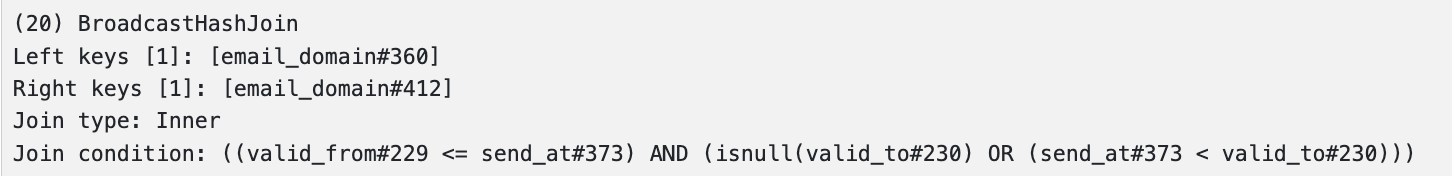
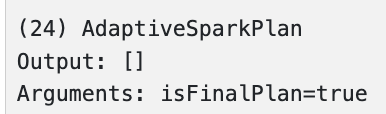

При включённом AQE физический план содержит оператор BroadcastHashJoin. Spark выполнил broadcast таблицы кампаний размером около 2 MiB (25 строк), после чего результат JOIN был записан в Parquet.

Параметр isFinalPlan=true подтверждает, что представлен финальный план после адаптации AQE.

Таким образом, автоматическая стратегия Spark выбрала Broadcast Hash Join, так как справочник кампаний содержит всего 25 записей и он значительно меньше таблицы истории пользователей. Поэтому Spark решил передать небольшую таблицу кампаний на все executors, избежав необходимости перераспределять обе таблицы между узлами кластера

## Статистики по времени

In [135]:
time_stat = measurements_df.groupby("strategy")["time_sec"].agg(median="median", min="min", max="max")

In [136]:
time_stat

,median,min,max
strategy,,,
Automatic,1.590935,1.393454,2.175421
Broadcast Hash,1.433632,1.291781,1.657278
Shuffled Hash,1.951241,1.778258,2.035740
Sort Merge,2.029843,1.648950,2.105973


# Выводы

- ### Какой вариант оказался быстрее и насколько результат устойчив относительно разброса?

Быстрее всего оказалась стратегия Broadcast Hash, она показала наименьшее время и по медине, и по минимальному, и по максимальному времени.

По устойчивости результатов лучшей оказалась Shuffled Hash, так как у нее минмальный разброс между максимальным и минимальным временем = 0,257 с. У Broadcast Hash разброс составил 0,365 с, у Sort Merge — 0,456 с, у Automatic — 0,782 с.

- ### Почему меньший shuffle мог не дать меньшего времени чтения, JOIN и записи?

Меньший Shuffle не гарантирует меньшего времени, потому что разные стратегии JOIN выполняют разный объём дополнительных операций. Например, Sort Merge Join требует сортировки данных, а Broadcast Hash Join — создания и рассылки хеш-таблицы. Эти операции тоже занимают время и могут перекрыть выигрыш от меньшего Shuffle.
Кроме того, во всех стратегиях записывается одинаковый результат — 500 233 строки, поэтому затраты на запись остаются существенными

- ### Какой план выбрал Spark без hints? Изменил ли явный broadcast этот план?

Spark выбрал Broadcast Hash Join, так как справочник кампаний содержит всего 25 записей и он значительно меньше таблицы истории пользователей. Поэтому Spark решил передать небольшую таблицу кампаний на все executors, избежав необходимости перераспределять обе таблицы между узлами кластера

Явный broadcast не изменил тип JOIN, поскольку Spark и без подсказки выбрал ту же стратегию

- ### Как пять доменов влияют на распределение данных? При каких изменениях нагрузки результат может стать другим?

Пять доменов означают, что данные распределяются по пяти основным группам по значению email_domain. Если распределение доменов неравномерное, одни группы могут содержать значительно больше пользователей, чем другие, что может привести к перекосу данных

Результат может измениться, если:
- увеличится количество пользователей или кампаний
- изменится соотношение данных между доменами
- появятся домены с существенно большим количеством пользователей
- увеличится размер справочника кампаний настолько, что его станет невыгодно передавать через broadcast

В таком случае Spark может выбрать другую стратегию JOIN, а производительность стратегий может измениться